# 01. Exploração dos dados (WFLW)

Antes de tomar qualquer decisão sobre o modelo, vale a pena olhar com calma para os dados.
Aqui a ideia é só **ler e entender** o WFLW: como as anotações estão organizadas, onde ficam
os 98 pontos, quais faces são difíceis e quantos olhos fechados existem. Recorte, divisão e
augmentation ficam para o notebook `02_preprocessamento`.

O que vamos ver:

1. Como as anotações estão escritas e como lê-las
2. Os 98 pontos e as regiões da face
3. Quantas faces por imagem, de que tamanho, e quais atributos difíceis aparecem
4. A abertura dos olhos (EAR) e os olhos fechados
5. Um resumo do que aprendemos

In [1]:
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 90

# raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                      # WFLW (espelho público no Kaggle, ver o README)
ANN, IMG = DATA / "WFLW_annotations", DATA / "WFLW_images"
PROCESSED = DATA / "processed"            # saídas do notebook 02

print(sorted(p.name for p in ANN.iterdir()))

['Mirror98.txt', 'list_98pt_rect_attr_train_test', 'list_98pt_test']


## 1. Como as anotações estão escritas

Cada linha dos arquivos `list_98pt_rect_attr_train.txt` e `list_98pt_rect_attr_test.txt`
descreve **uma face**, e não uma imagem inteira. Uma linha tem 207 campos:

| Campos | O que guardam |
|---|---|
| 0 a 195 | os 98 pontos, como pares (x, y) em pixels da imagem original |
| 196 a 199 | o retângulo da face: x mínimo, y mínimo, x máximo, y máximo |
| 200 a 205 | seis atributos que valem 0 ou 1: pose, expressão, iluminação, maquiagem, oclusão e desfoque |
| 206 | o caminho da imagem |

In [2]:
ATTRIBUTES = ["pose", "expressão", "iluminação", "maquiagem", "oclusão", "desfoque"]


def annotation_file(split):
    return ANN / "list_98pt_rect_attr_train_test" / f"list_98pt_rect_attr_{split}.txt"


def read_split(split):
    # Lê um split inteiro como arrays (uma posição por FACE).
    rows = [line.split() for line in annotation_file(split).read_text().splitlines()]
    return {
        "landmarks": np.array([r[:196] for r in rows], np.float32).reshape(-1, 98, 2),
        "box": np.array([r[196:200] for r in rows], np.float32),
        "attr": np.array([r[200:206] for r in rows], np.int64),
        "image": np.array([r[206] for r in rows]),
    }


first = annotation_file("train").read_text().splitlines()[0].split()
print("campos por linha:", len(first))
print("primeiros pontos:", first[:6], "...")
print("retângulo:", first[196:200], "| atributos:", first[200:206], "| imagem:", first[206])

train = read_split("train")
test = read_split("test")
for name, d in [("treino", train), ("teste", test)]:
    print(f"{name:6s}: {len(d['box']):5d} faces em {len(set(d['image'])):5d} imagens")

campos por linha: 207
primeiros pontos: ['309.307007', '538.369019', '317.857345', '560.120847', '322.271739', '583.014395'] ...
retângulo: ['306', '308', '696', '870'] | atributos: ['0', '0', '1', '0', '0', '0'] | imagem: 51--Dresses/51_Dresses_wearingdress_51_377.jpg


treino:  7500 faces em  5316 imagens
teste :  2500 faces em  2118 imagens


## 2. Os 98 pontos e as regiões da face

Para detectar sonolência, o que mais interessa são os **olhos**, que vão do ponto 60 ao 75,
com 8 pontos em cada olho. Um detalhe que confunde no começo: o ponto 60 é o canto de fora
do olho **direito da pessoa**, e esse olho aparece do **lado esquerdo da imagem**. O ponto 72
é o canto de fora do outro olho. A distância entre 60 e 72 é a que usamos para normalizar o
erro (NME), assim o erro não depende do tamanho da face.

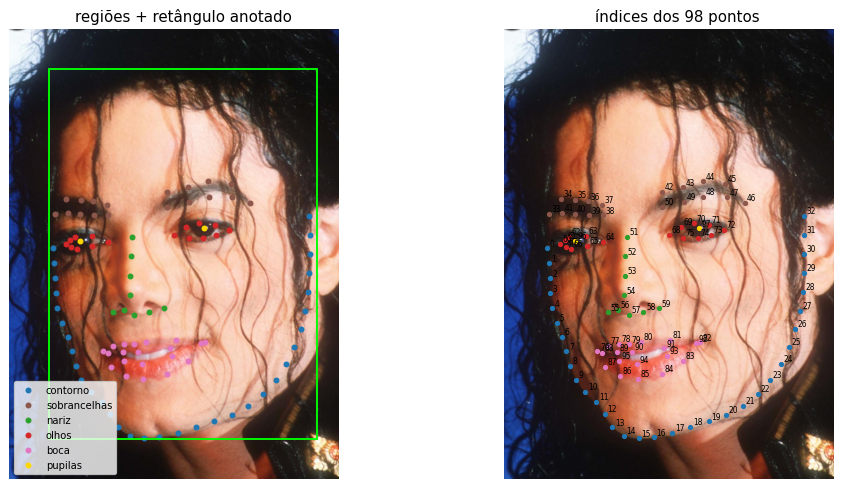

In [3]:
REGIONS = {
    "contorno": range(0, 33), "sobrancelhas": range(33, 51), "nariz": range(51, 60),
    "olhos": range(60, 76), "boca": range(76, 96), "pupilas": range(96, 98),
}
COLORS = dict(zip(REGIONS, ["tab:blue", "tab:brown", "tab:green", "tab:red", "tab:pink", "gold"]))


def draw_points(ax, pts, s=8, numbers=False):
    for name, idx in REGIONS.items():
        idx = list(idx)
        ax.scatter(pts[idx, 0], pts[idx, 1], s=s, c=COLORS[name], label=name)
        if numbers:
            for i in idx:
                ax.annotate(str(i), pts[i], fontsize=6, xytext=(2, 2), textcoords="offset points")


def load_rgb(rel):
    return cv2.cvtColor(cv2.imread(str(IMG / rel)), cv2.COLOR_BGR2RGB)


# uma face frontal, sem atributos difíceis e grande, para ver bem os pontos
i = int(np.argmax((train["attr"].sum(1) == 0) * (train["box"][:, 2] - train["box"][:, 0])))
img, pts, box = load_rgb(train["image"][i]), train["landmarks"][i], train["box"][i]
x0, y0, x1, y1 = box
pad = 0.15 * (x1 - x0)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, numbers in zip(axes, [False, True]):
    ax.imshow(img)
    draw_points(ax, pts, s=10 if numbers else 14, numbers=numbers)
    ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y1 + pad, y0 - pad); ax.axis("off")
axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5))
axes[0].legend(loc="lower left", fontsize=8)
axes[0].set_title("regiões + retângulo anotado"); axes[1].set_title("índices dos 98 pontos")
plt.show()

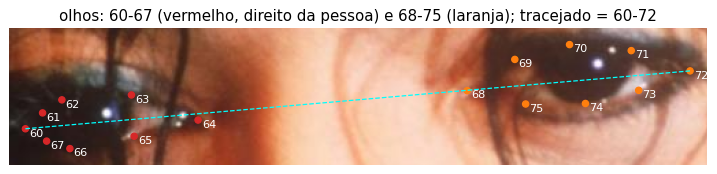

In [4]:
# zoom nos olhos
eyes = pts[60:76]
(ex0, ey0), (ex1, ey1) = eyes.min(0) - 12, eyes.max(0) + 12
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.imshow(img)
ax.scatter(eyes[:, 0], eyes[:, 1], c=["tab:red"] * 8 + ["tab:orange"] * 8, s=25)
for k in range(60, 76):
    ax.annotate(str(k), pts[k], fontsize=9, xytext=(3, -6), textcoords="offset points", color="w")
ax.plot(*pts[[60, 72]].T, "--", c="cyan", lw=1)
ax.set_xlim(ex0, ex1); ax.set_ylim(ey1, ey0); ax.axis("off")
ax.set_title("olhos: 60-67 (vermelho, direito da pessoa) e 68-75 (laranja); tracejado = 60-72")
plt.show()

## 3. Faces por imagem, tamanhos e atributos

Algumas imagens são fotos de multidão, com várias pessoas. Por isso o dataset é organizado
com **uma amostra por face**. Também vale comparar treino e teste, porque o teste do WFLW foi
montado de propósito para ser mais difícil.

treino: faces/imagem máx = 18 | lado da caixa mediana = 136 px (p5-p95: 75-480)
teste : faces/imagem máx =  6 | lado da caixa mediana = 130 px (p5-p95: 74-460)


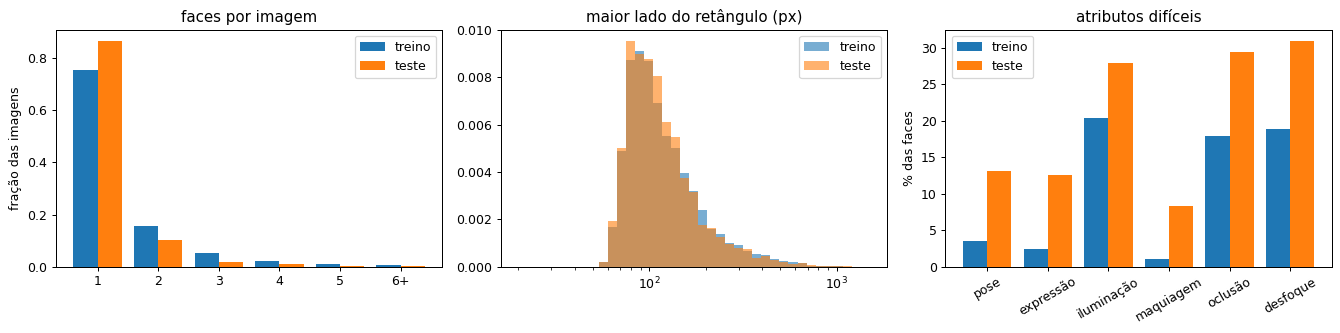

treino: 48.9 % das faces têm algum atributo difícil
teste : 78.6 % das faces têm algum atributo difícil


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, d, c in [("treino", train, "tab:blue"), ("teste", test, "tab:orange")]:
    per_image = np.array(list(Counter(d["image"]).values()))
    k, n = np.unique(np.minimum(per_image, 6), return_counts=True)
    axes[0].bar(k + (0.2 if name == "teste" else -0.2), n / n.sum(), 0.4, label=name, color=c)
    side = np.maximum(d["box"][:, 2] - d["box"][:, 0], d["box"][:, 3] - d["box"][:, 1])
    axes[1].hist(side, bins=np.geomspace(20, 1500, 40), alpha=0.6, density=True, label=name, color=c)
    print(f"{name:6s}: faces/imagem máx = {per_image.max():2d} | lado da caixa mediana = "
          f"{np.median(side):.0f} px (p5-p95: {np.percentile(side, 5):.0f}-{np.percentile(side, 95):.0f})")
axes[0].set_xticks(range(1, 7), ["1", "2", "3", "4", "5", "6+"])
axes[0].set_title("faces por imagem"); axes[0].set_ylabel("fração das imagens"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_title("maior lado do retângulo (px)"); axes[1].legend()
x = np.arange(6)
for off, name, d, c in [(-0.2, "treino", train, "tab:blue"), (0.2, "teste", test, "tab:orange")]:
    axes[2].bar(x + off, 100 * d["attr"].mean(0), 0.4, label=name, color=c)
axes[2].set_xticks(x, ATTRIBUTES, rotation=30); axes[2].set_ylabel("% das faces")
axes[2].set_title("atributos difíceis"); axes[2].legend()
plt.tight_layout(); plt.show()

for name, d in [("treino", train), ("teste", test)]:
    print(f"{name:6s}: {100 * (d['attr'].sum(1) > 0).mean():.1f} % das faces têm algum atributo difícil")

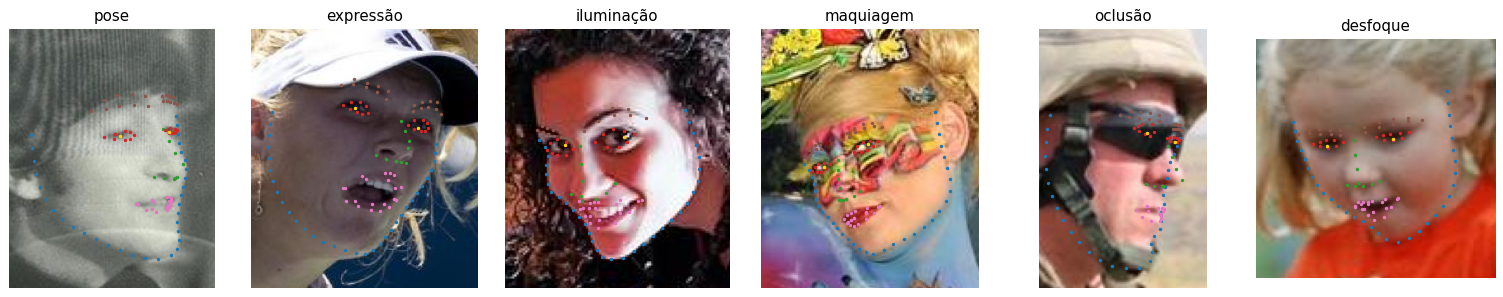

In [6]:
# um exemplo de cada atributo difícil (no teste)
fig, axes = plt.subplots(1, 6, figsize=(17, 3.4))
rng = np.random.default_rng(0)
for j, ax in enumerate(axes):
    k = rng.choice(np.where(test["attr"][:, j] == 1)[0])
    x0, y0, x1, y1 = test["box"][k]; pad = 0.2 * (x1 - x0)
    ax.imshow(load_rgb(test["image"][k])); draw_points(ax, test["landmarks"][k], s=3)
    ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y1 + pad, y0 - pad); ax.axis("off")
    ax.set_title(ATTRIBUTES[j])
plt.tight_layout(); plt.show()

O teste tem pose quase **quatro vezes** mais frequente do que o treino, e expressão mais de
**cinco vezes**. Isso
significa que o erro no teste deve sair maior do que na validação (que é tirada do treino), e
que faces viradas devem ser o caso mais difícil.

## 4. A abertura dos olhos (EAR) e os olhos fechados

O **Eye Aspect Ratio** (Soukupová e Čech, 2016) mede o quanto o olho está aberto comparando
as distâncias na vertical com a largura do olho:

$$\mathrm{EAR} = \frac{\lVert p_2 - p_6\rVert + \lVert p_3 - p_5\rVert}{2\,\lVert p_1 - p_4\rVert}$$

No WFLW usamos os pontos 60, 61, 63, 64, 65 e 67 no olho direito e os pontos correspondentes
72, 71, 69, 68, 75 e 73 no esquerdo, e tiramos a média dos dois olhos. Como é uma razão entre
distâncias, o valor não muda se a face estiver perto ou longe da câmera.

        mediana | EAR<0,10 | EAR<0,15 | EAR<0,20
treino  0.258  |    4.1 % |    8.8 % |   21.0 %
teste   0.265  |    5.7 % |   11.0 % |   22.1 %


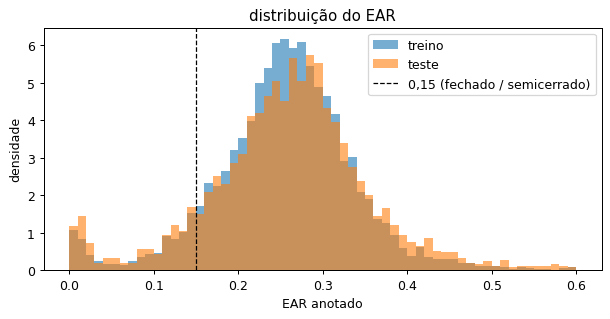

In [ ]:
EAR_RIGHT = (60, 61, 63, 64,  65, 67)   # p1..p6 do olho direito da pessoa
EAR_LEFT = (72, 71, 69, 68, 75, 73)    # espelho pelo Mirror98


def ear_eye(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[..., i, :] for i in idx)
    n = lambda a, b: np.linalg.norm(a - b, axis=-1)
    return (n(p2, p6) + n(p3, p5)) / (2 * n(p1, p4) + 1e-9)


def ear(p):
    return (ear_eye(p, EAR_RIGHT) + ear_eye(p, EAR_LEFT)) / 2


ear_train, ear_test = ear(train["landmarks"]), ear(test["landmarks"])
print("        mediana | EAR<0,10 | EAR<0,15 | EAR<0,20")
for name, e in [("treino", ear_train), ("teste ", ear_test)]:
    print(f"{name}  {np.median(e):.3f}  | " + " | ".join(f"{100 * (e < t).mean():6.1f} %" for t in [0.10, 0.15, 0.20]))

plt.figure(figsize=(8, 3.5))
bins = np.linspace(0, 0.6, 61)
plt.hist(ear_train, bins, alpha=0.6, density=True, label="treino")
plt.hist(ear_test, bins, alpha=0.6, density=True, label="teste")
plt.axvline(0.15, c="k", ls="--", lw=1, label="0,15 (fechado / semicerrado)")
plt.xlabel("EAR anotado"); plt.ylabel("densidade"); plt.legend(); plt.title("distribuição do EAR")
plt.show()

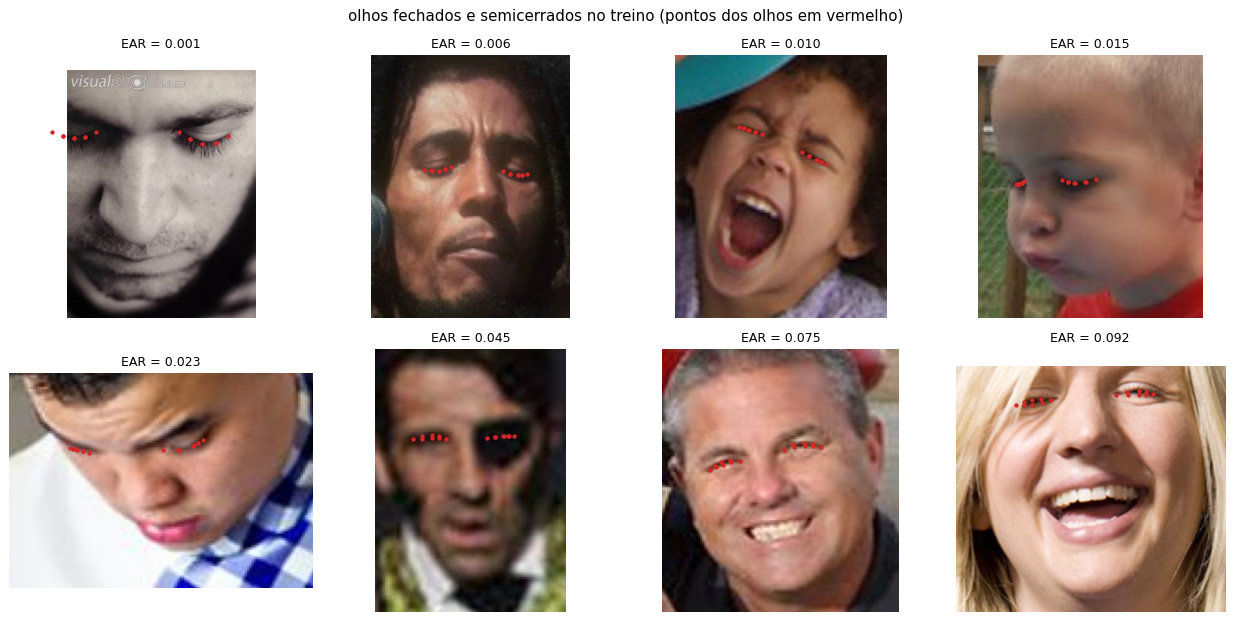

In [8]:
# faces de treino com os olhos mais fechados (do menor EAR para cima)
order = np.argsort(ear_train)[::40][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, k in zip(axes.flat, order):
    x0, y0, x1, y1 = train["box"][k]; pad = 0.1 * (x1 - x0)
    ax.imshow(load_rgb(train["image"][k]))
    q = train["landmarks"][k]
    ax.scatter(q[60:76, 0], q[60:76, 1], s=6, c="tab:red")
    ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y1 + pad, y0 - pad); ax.axis("off")
    ax.set_title(f"EAR = {ear_train[k]:.3f}", fontsize=10)
plt.suptitle("olhos fechados e semicerrados no treino (pontos dos olhos em vermelho)")
plt.tight_layout(); plt.show()

## 5. O que aprendemos

| O que vimos | O que isso muda no projeto |
|---|---|
| São 7.500 faces de treino em 5.316 imagens, com até 18 faces na mesma foto | o dataset precisa ser indexado por **face** |
| O teste é bem mais difícil: 79 % das faces têm algum atributo difícil, contra 49 % no treino | a validação, tirada do treino, vai parecer mais fácil do que o teste |
| Só cerca de 9 % das faces de treino têm EAR abaixo de 0,15 | olhos fechados são **minoria**, e o modelo corre o risco de aprender a desenhar sempre um olho aberto |

No próximo notebook, `02_preprocessamento.ipynb`, transformamos essas faces em entradas para o modelo.